# Baseline 2 — Exp18: cRT repeat seeds (conditional on Exp09 frozen backbone)

**Research question:** Does the encouraging Exp17 cRT improvement persist under different **head reinitialization, augmentation and sampler random seeds**?

- This notebook repeats **the exact Exp17 recipe** at seed 123 or seed 2026: Exp09 seed42 parent ResNet-50 checkpoint; frozen shared backbone and crop head including BatchNorm buffers; reinitialized and separately trained disease head with tempered disease sampling α=0.5.
- **Important limit:** The parent Exp09 representation stays fixed at seed 42. These are **conditional cRT-head repeats**, NOT end-to-end independent backbone-seed repetitions. To test the latter, train independent Exp09 parents per seed first, then cRT each matching parent.
- The existing Exp17 seed42 is the third point of comparison. Classifier head, sampler, augmentation and DataLoader RNG change with seed; the 6,905/695/400 development split stays identical.
- Each run trains **one seed only** using `EXPERIMENT_TO_RUN` in Section 1. Save each run in its own folder. Never automatically run both seeds or overwrite Exp17.
- Stage 1 *development only*. No Stage 2 and no official test. Best checkpoint is selected by highest seen/unseen development composition HM.
- All-pairs inference with 9,625 candidates is unchanged. Development repeats are exploratory and do not provide independent test evidence.

Reference for the general idea: Kang et al. (2020), *Decoupling Representation and Classifier for Long-Tailed Recognition*, https://arxiv.org/abs/1910.09217. This one-head-only multi-task adaptation is our own experimental variation.


## 1. Choose one Exp18 cRT seed and run preflight

Requires `model_resnet50.py`, `evaluate.py`, `splits_v2` and the **same Exp09 seed42 parent checkpoint** as Exp17. Defaults to seed123; after it finishes, set selector to `exp18_crt_seed2026`, restart kernel and Run All once. No combined training job.


In [1]:
from pathlib import Path
from dataclasses import dataclass
import copy
import gc
import json
import math
import platform
import random
import tempfile
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode

from model_resnet50 import MultiTaskResNet50, load_resnet50_checkpoint as load_checkpoint
from evaluate import (DPDDataset, MEAN, STD, evaluate_loader, generalisation_metrics,
                      validate_development_splits, validation_transform,
                      make_candidates, require_candidate_coverage,
                      sha256_file, synthetic_self_test)

PROJECT_DIR = Path.cwd()
SPLIT_DIR = PROJECT_DIR / "splits_v2"
DATASET_ROOT = PROJECT_DIR.parent / "DPD_Small_dataset"
IMAGE_ROOT = DATASET_ROOT
OUTPUT_ROOT = PROJECT_DIR / "outputs"

# ONE experiment per Run All; change only this selector for a later, optional run.
EXPERIMENT_TO_RUN = "exp18_crt_seed123"  # next run: "exp18_crt_seed2026"

BASE_CONFIG = {
    "backbone": "resnet50", "pretrained_weights": "IMAGENET1K_V2",
    "crop_classes": 55, "disease_classes": 175, "image_size": 224,
    "batch_size": 16, "max_epochs": 30, "patience": 15, "min_delta": 1e-6,
    "backbone_lr": 1e-5, "head_lr": 1e-3, "crop_dropout": 0.3, "disease_dropout": 0.2,
    "weight_decay": 1e-3, "optimizer": "AdamW", "scheduler": "CosineAnnealingLR",
    "crop_loss_weight": 1.0, "disease_loss_weight": 1.0,
    "seed": 42, "num_workers": 4, "amp": True,
    "crop_scale": [0.85, 1.0], "flip_probability": 0.5, "vertical_flip_probability": 0.5,
    "rotation_degrees": 10, "brightness": 0.15, "contrast": 0.15,
    "interpolation": "bilinear_resize_nearest_rotation", "mean": list(MEAN), "std": list(STD),
    "candidate_mode": "all_pairs", "candidate_catalog": None,
}
EXPERIMENTS = {
    "exp18_crt_seed123": {
        "changed_parameter": "Repeat Exp17 cRT recipe, change random seed 42 -> 123 (same Exp09 seed42 frozen parent)",
        "sampling_method": "tempered_disease", "sampling_alpha": 0.5,
        "disease_loss_method": "cross_entropy", "disease_cb_beta": None,
        "crop_loss_weight": 0.0, "disease_loss_weight": 1.0,
        "trainable_components": ["disease_head"],
        "source_experiment": "b2_resnet50_exp09_b1matched_seed42",
        "seed": 123,
    },
    "exp18_crt_seed2026": {
        "changed_parameter": "Repeat Exp17 cRT recipe, change random seed 42 -> 2026 (same Exp09 seed42 frozen parent)",
        "sampling_method": "tempered_disease", "sampling_alpha": 0.5,
        "disease_loss_method": "cross_entropy", "disease_cb_beta": None,
        "crop_loss_weight": 0.0, "disease_loss_weight": 1.0,
        "trainable_components": ["disease_head"],
        "source_experiment": "b2_resnet50_exp09_b1matched_seed42",
        "seed": 2026,
    },
}
if EXPERIMENT_TO_RUN not in EXPERIMENTS:
    raise ValueError(f"Choose one of {list(EXPERIMENTS)}")
CONFIG = {**BASE_CONFIG, **EXPERIMENTS[EXPERIMENT_TO_RUN], "experiment_id": EXPERIMENT_TO_RUN}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EXP09_DIR = OUTPUT_ROOT / "b2_resnet50_exp09_b1matched_seed42"
EXP10_DIR = OUTPUT_ROOT / "exp10"
SOURCE_CKPT = EXP09_DIR / "best_development.pt"
EXPERIMENT_DIR = OUTPUT_ROOT / EXPERIMENT_TO_RUN
RUN_AUTO_AUDIT = True
print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
print("Selected:", EXPERIMENT_TO_RUN)
print(json.dumps(CONFIG, indent=2))
if DEVICE.type != "cuda":
    raise RuntimeError("CUDA GPU unavailable. STOP; do not train for hours on CPU.")
print("GPU:", torch.cuda.get_device_name(0))
if not IMAGE_ROOT.is_dir() or not SPLIT_DIR.is_dir():
    raise FileNotFoundError("Dataset or splits_v2 folder is missing; ensure notebook is in Baseline2 project root")
if EXPERIMENT_DIR.exists():
    raise FileExistsError(f"Output already exists: {EXPERIMENT_DIR}. Review old run; never silently overwrite it.")
gpu_free_bytes, gpu_total_bytes = torch.cuda.mem_get_info()
print(f"CUDA free VRAM: {gpu_free_bytes / 2**30:.2f}/{gpu_total_bytes / 2**30:.2f} GiB")
if gpu_free_bytes < 3*2**30:
    raise RuntimeError("Less than 3 GiB free VRAM. Close stale processes and restart kernel first.")
assert CONFIG["sampling_method"] == "tempered_disease"
assert CONFIG["crop_loss_weight"] == 0.0 and CONFIG["disease_loss_weight"] == 1.0
if not SOURCE_CKPT.is_file():
    raise FileNotFoundError("Exp09 parent checkpoint not found: " + str(SOURCE_CKPT))
print("PREFLIGHT PASSED: will train ONE cRT repeat seed using frozen Exp09 weights.")


PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Selected: exp18_crt_seed123
{
  "backbone": "resnet50",
  "pretrained_weights": "IMAGENET1K_V2",
  "crop_classes": 55,
  "disease_classes": 175,
  "image_size": 224,
  "batch_size": 16,
  "max_epochs": 30,
  "patience": 15,
  "min_delta": 1e-06,
  "backbone_lr": 1e-05,
  "head_lr": 0.001,
  "crop_dropout": 0.3,
  "disease_dropout": 0.2,
  "weight_decay": 0.001,
  "optimizer": "AdamW",
  "scheduler": "CosineAnnealingLR",
  "crop_loss_weight": 0.0,
  "disease_loss_weight": 1.0,
  "seed": 123,
  "num_workers": 4,
  "amp": true,
  "crop_scale": [
    0.85,
    1.0
  ],
  "flip_probability": 0.5,
  "vertical_flip_probability": 0.5,
  "rotation_degrees": 10,
  "brightness": 0.15,
  "contrast": 0.15,
  "interpolation": "bilinear_resize_nearest_rotation",
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "candidate_mode": "all_pairs",
  "candidate_catalog": null,
  "changed_parameter": "Repeat Exp1

## 2. Verify development splits and class mappings

Same train/validation split and label mapping as Exp09; train 6,905, seen-val 695, unseen-val 400. Validation never used for weight adjustment or training. No official test.


In [2]:
frames, split_report = validate_development_splits(SPLIT_DIR)
print(json.dumps(split_report, indent=2))
canonical_metadata = pd.concat(frames.values(), ignore_index=True)
class_mappings = {
    task: {str(int(row[0])): str(row[1]) for row in
           canonical_metadata[[f"{task}_id", f"{task}_name"]].drop_duplicates().itertuples(index=False, name=None)}
    for task in ("crop", "disease", "composition")
}
composition_mapping = canonical_metadata[
    ["composition_id", "crop_id", "disease_id", "composition_name"]
].drop_duplicates().sort_values("composition_id").to_dict(orient="records")
print("Original IDs retained; no new class numbering.")


{
  "counts": {
    "train_fit": 6905,
    "val_seen": 695,
    "val_unseen": 400
  },
  "coverage": {
    "train_fit": {
      "crop_id": 55,
      "disease_id": 175,
      "composition_id": 313
    },
    "val_seen": {
      "crop_id": 55,
      "disease_id": 155,
      "composition_id": 273
    },
    "val_unseen": {
      "crop_id": 10,
      "disease_id": 8,
      "composition_id": 10
    }
  },
  "sha256": {
    "train_fit.csv": "fe02d6099c002b10e5a428c2260d5de50f3e677d3b7454216b2a340e55c2a377",
    "val_seen.csv": "ab8d18a13b28fd5a7b9ea531b8ffbdcf4174fd6920337ee9f1a726129390daf5",
    "val_unseen.csv": "b9eae2a57d8331d97636f4e8a8e32bc2e81704d7180fdac22ae923273aadec67",
    "heldout_compositions.csv": "437f57924eef3e5788ed0993caddd969e08f9f86add64791d944425f4bddfe7f",
    "split_manifest.json": "c120d065677e37db6d00880104684c0cd70ccd1c0774ec4aac2eb4b4b0889df8"
  },
  "image_paths_checked": false
}
Original IDs retained; no new class numbering.


## 3. Augmentation, evaluation transforms and 9,625 candidate pairs

Identical to Exp09/Exp10: training RandomResizedCrop + flips + small rotation/color jitter; evaluation Resize(256) + CenterCrop(224); ImageNet normalization. Changing these would confound the intervention.

In [3]:
def training_transform(config):
    return T.Compose([
        T.RandomResizedCrop(config["image_size"], scale=tuple(config["crop_scale"]),
                            interpolation=InterpolationMode.BILINEAR),
        T.RandomHorizontalFlip(p=config["flip_probability"]),
        T.RandomVerticalFlip(p=config["vertical_flip_probability"]),
        T.RandomRotation(config["rotation_degrees"], interpolation=InterpolationMode.NEAREST),
        T.ColorJitter(brightness=config["brightness"], contrast=config["contrast"]),
        T.ToTensor(), T.Normalize(MEAN, STD),
    ])

def evaluation_transform(image_size):
    resized = round(image_size * 256 / 224)
    return T.Compose([
        T.Resize(resized, interpolation=InterpolationMode.BILINEAR),
        T.CenterCrop(image_size),
        T.ToTensor(), T.Normalize(MEAN, STD),
    ])


candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
require_candidate_coverage(candidates, list(frames.values()))
print(f"Candidate mode: {CONFIG['candidate_mode']}; {len(candidates):,} global candidate pairs")
if CONFIG["candidate_mode"] == "all_pairs":
    print("PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.")

Candidate mode: all_pairs; 9,625 global candidate pairs
PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.


## 4. Same train-fit split, cRT balanced disease sampler and checkpoint I/O

`WeightedRandomSampler` uses only train-fit disease counts; α=0.5. All 55 crop and 175 disease IDs remain identical to Exp09. The original Exp09 checkpoint and output are read-only. Validation splits have no resampling and never enter optimizer updates.


In [4]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def make_loader(dataset, config, shuffle=False, sampler=None):
    workers = int(config["num_workers"])
    if workers < 0:
        raise ValueError("num_workers must be >= 0")
    generator = torch.Generator().manual_seed(config["seed"])
    if shuffle and sampler is not None:
        raise ValueError("Cannot enable both shuffle and sampler")
    kwargs = dict(batch_size=config["batch_size"], shuffle=shuffle, sampler=sampler,
                  num_workers=workers, pin_memory=DEVICE.type == "cuda",
                  generator=generator, drop_last=False)
    if workers > 0:
        kwargs["prefetch_factor"] = 2
        kwargs["persistent_workers"] = True
    return DataLoader(dataset, **kwargs)


@dataclass
class EarlyStopping:
    patience: int = 5
    min_delta: float = 1e-6
    best: float = -math.inf
    bad_epochs: int = 0

    def update(self, value):
        if not math.isfinite(value):
            raise ValueError("Nonfinite validation harmonic mean")
        improved = value > self.best + self.min_delta
        if improved:
            self.best = value
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return improved, self.bad_epochs >= self.patience


def atomic_checkpoint(payload, path):
    path = Path(path)
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def environment_details():
    return {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "numpy": np.__version__,
            "pandas": pd.__version__, "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
            "cuda_runtime": torch.version.cuda}


def make_tempered_disease_sampler(training_frame, alpha=0.25, seed=42):
    """Compute per-image weights exclusively from the existing train-fit labels."""
    if not (0 <= alpha <= 1):
        raise ValueError("alpha must be in [0,1]")
    frequency = training_frame["disease_id"].value_counts()
    if (frequency <= 0).any() or len(training_frame) != 6905:
        raise ValueError("Unexpected train-fit disease frequency / split size")
    per_image_counts = training_frame["disease_id"].map(frequency)
    weights = torch.as_tensor(per_image_counts.to_numpy(dtype=float) ** (-alpha), dtype=torch.double)
    assert len(weights) == len(training_frame) and torch.isfinite(weights).all()
    sampler = torch.utils.data.WeightedRandomSampler(
        weights=weights, num_samples=len(training_frame), replacement=True,
        generator=torch.Generator().manual_seed(seed))
    # Approximate expected draws per label (not a guarantee about realised sampled counts).
    expected = (pd.DataFrame({"disease_id":frequency.index.astype(int),
                 "train_images":frequency.values.astype(int)}).sort_values("disease_id"))
    numerators = expected["train_images"].to_numpy(dtype=float) ** (1-alpha)
    expected["expected_draws_per_epoch"] = len(training_frame) * numerators / numerators.sum()
    return sampler, expected



## 5. Small CPU synthetic cRT gradient test (no pretrained weights or CUDA memory usage)

Prove gradient updates only the disease classifier while frozen crop and backbone representations stay unchanged. The real Exp09 checkpoint and config are validated in Section 7.


In [5]:
def run_crt_smoke_checks():
    synthetic_self_test()
    seed_everything(CONFIG["seed"])
    smoke_device=torch.device("cpu")
    # Fast miniature proxy: prevents an unnecessary whole-ResNet CPU forward.
    backbone=nn.Sequential(nn.Linear(6,4), nn.BatchNorm1d(4)).to(smoke_device)
    crop=nn.Linear(4,55).to(smoke_device)
    disease=nn.Linear(4,175).to(smoke_device)
    for mod in (backbone,crop):
        mod.eval()
        for p in mod.parameters(): p.requires_grad_(False)
    disease.train()
    before_b={k:v.detach().clone() for k,v in backbone.state_dict().items()}
    before_c={k:v.detach().clone() for k,v in crop.state_dict().items()}
    opt=torch.optim.AdamW(disease.parameters(),lr=1e-3)
    x=torch.randn(3,6)
    y=torch.tensor([0,1,2])
    with torch.no_grad(): z=backbone(x)
    loss=nn.functional.cross_entropy(disease(z),y)
    loss.backward()
    assert all(p.grad is not None for p in disease.parameters())
    assert all(p.grad is None for p in list(backbone.parameters())+list(crop.parameters()))
    opt.step()
    assert all(torch.equal(v, before_b[k]) for k,v in backbone.state_dict().items())
    assert all(torch.equal(v, before_c[k]) for k,v in crop.state_dict().items())
    print("CPU synthetic cRT gradient/freeze check passed. Full GPU training uses Exp09 frozen backbone.")

run_crt_smoke_checks()


Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
CPU synthetic cRT gradient/freeze check passed. Full GPU training uses Exp09 frozen backbone.


## 6. Exp18 cRT trainer: freeze Exp09 backbone and crop head, reset/train only disease head

This is the **same implementation as Exp17**, with different RNG seed. BatchNorm running statistics stay frozen (`backbone.eval()`, no-gradient forward) and crop parameters are unchanged. Each run independently resets the disease linear head and runs α=0.5 disease sampling. Checkpoint selection still uses highest development composition HM.


In [6]:
def train_crt_epoch(model, loader, optimizer, scaler, device, amp=True):
    model.backbone.eval()   # Important: frozen BatchNorm running stats
    model.crop_head.eval()  # No crop gradients or dropout changes in frozen crop branch
    model.disease_head.train()
    assert all(not p.requires_grad for p in model.backbone.parameters())
    assert all(not p.requires_grad for p in model.crop_head.parameters())
    assert all(p.requires_grad for p in model.disease_head.parameters())
    total, count = 0.0, 0
    for batch in loader:
        images=batch["image"].to(device,non_blocking=True)
        disease=batch["disease"].to(device,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        try:
            with torch.no_grad():
                with torch.autocast(device_type=device.type,enabled=amp and device.type=="cuda"):
                    feat=model.backbone(images)
            with torch.autocast(device_type=device.type,enabled=amp and device.type=="cuda"):
                pred=model.disease_head(feat.detach())
                loss=nn.functional.cross_entropy(pred,disease)
            if not torch.isfinite(loss):
                raise RuntimeError("Nonfinite cRT disease loss")
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.cuda.OutOfMemoryError as e:
            raise RuntimeError("CUDA OOM in Exp18 cRT; restart kernel, check GPU memory. Do not silently change settings.") from e
        n=images.shape[0]
        total+=n*float(loss.item());count+=n
    if not count:raise ValueError("Empty training loader")
    return {"total_loss":total/count,"crop_loss":float("nan"),"disease_loss":total/count}


def plot_crt_history(history,best_epoch,path):
    t=pd.DataFrame(history)
    fig,axes=plt.subplots(2,2,figsize=(12,8))
    axes[0,0].plot(t.epoch,t.train_disease_loss,label="Train disease CE")
    axes[0,0].plot(t.epoch,t.seen_disease_loss,label="Seen disease CE")
    axes[0,0].plot(t.epoch,t.unseen_disease_loss,label="Unseen disease CE")
    axes[0,0].set(title="Disease loss (frozen representation)",ylabel="Cross-entropy")
    axes[0,1].plot(t.epoch,t.seen_disease_top1*100,label="Seen")
    axes[0,1].plot(t.epoch,t.unseen_disease_top1*100,label="Unseen")
    axes[0,1].set(title="Disease Top-1",ylabel="Accuracy (%)")
    axes[1,0].plot(t.epoch,t.seen_composition_top1*100,label="Seen")
    axes[1,0].plot(t.epoch,t.unseen_composition_top1*100,label="Unseen")
    axes[1,0].set(title="Composition Top-1",ylabel="Accuracy (%)")
    axes[1,1].plot(t.epoch,t.composition_harmonic_mean*100,label="Development HM")
    axes[1,1].set(title="Checkpoint selection metric",ylabel="HM (%)")
    for ax in axes.flat:
        ax.axvline(best_epoch,ls="--",color="black",alpha=.5,label=f"best {best_epoch}")
        ax.set_xlabel("Epoch");ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(path,dpi=160)
    return fig


def fit_crt_stage1(config, train_loader, seen_loader, unseen_loader,
                   candidate_pairs, metadata_report, mappings, composition_map,
                   source_ckpt=SOURCE_CKPT, output_root=OUTPUT_ROOT):
    seed_everything(config["seed"])
    # Source verification: never accidentally initialise fresh ImageNet weights.
    model, parent=load_checkpoint(source_ckpt,DEVICE)
    if parent.get("stage")!=1 or parent.get("config",{}).get("experiment_id")!=config["source_experiment"]:
        raise ValueError("Wrong source checkpoint; expected Exp09 Stage 1")
    if parent.get("development_split",{}).get("sha256")!=metadata_report.get("sha256"):
        raise ValueError("Exp09 and Exp18 cRT split hashes differ")
    if not torch.equal(torch.as_tensor(parent["candidate_pairs"]),candidate_pairs.cpu()):
        raise ValueError("Exp09 candidate list differs from Exp18 cRT")
    # Save unmodified reference state for verifying only the disease head moved.
    source_hash=sha256_file(source_ckpt)
    source_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()
                  if not k.startswith("disease_head.")}
    for mod in (model.backbone,model.crop_head):
        mod.eval()
        for p in mod.parameters():p.requires_grad_(False)
    seed_everything(config["seed"])
    model.disease_head[1].reset_parameters()
    model.disease_head.train()
    assert sum(p.numel() for p in model.parameters() if p.requires_grad)==(2048*175+175)
    optimizer=torch.optim.AdamW(model.disease_head.parameters(),lr=config["head_lr"],weight_decay=config["weight_decay"])
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=config["max_epochs"])
    amp_enabled=config["amp"] and DEVICE.type=="cuda"
    scaler=torch.amp.GradScaler("cuda",enabled=amp_enabled)
    stopper=EarlyStopping(config["patience"],config["min_delta"])
    output_dir=Path(output_root)/config["experiment_id"]
    output_dir.mkdir(parents=True,exist_ok=False)
    run_config=copy.deepcopy(config)
    environment=environment_details()
    (output_dir/"config.json").write_text(json.dumps({
        "config":run_config,"environment":environment,"development_split":metadata_report,
        "class_mappings":mappings,"composition_mapping":composition_map,
        "candidate_pairs":candidate_pairs.cpu().tolist(),
        "source_checkpoint":str(source_ckpt),"source_checkpoint_sha256":source_hash,
        "accuracy_units":"fractions in [0,1]"},indent=2),encoding="utf-8")
    history=[]; start=time.perf_counter();best_epoch=None
    for epoch in range(1,config["max_epochs"]+1):
        epoch_start=time.perf_counter()
        lr=optimizer.param_groups[0]["lr"]
        training=train_crt_epoch(model,train_loader,optimizer,scaler,DEVICE,amp_enabled)
        seen,_=evaluate_loader(model,seen_loader,DEVICE,candidate_pairs,amp_enabled)
        unseen,_=evaluate_loader(model,unseen_loader,DEVICE,candidate_pairs,amp_enabled)
        joint=generalisation_metrics(seen,unseen)
        row={"epoch":epoch,"backbone_lr":0.0,"head_lr":lr,
             **{f"train_{k}":v for k,v in training.items()},
             **{f"seen_{k}":v for k,v in seen.items()},
             **{f"unseen_{k}":v for k,v in unseen.items()},
             "composition_harmonic_mean":joint["composition_harmonic_mean"],
             "seen_unseen_gap":joint["seen_unseen_gap"],
             "epoch_seconds":time.perf_counter()-epoch_start}
        history.append(row)
        pd.DataFrame(history).to_csv(output_dir/"training_history.csv",index=False)
        improved,stop=stopper.update(joint["composition_harmonic_mean"])
        scheduler.step()
        if improved:
            best_epoch=epoch
            best_metrics={"epoch":epoch,"seen":seen,"unseen":unseen,**joint}
            atomic_checkpoint({"stage":1,"epoch":epoch,"model_state":model.state_dict(),
                "optimizer_state":optimizer.state_dict(),"scheduler_state":scheduler.state_dict(),
                "scaler_state":scaler.state_dict(),"config":run_config,
                "candidate_pairs":candidate_pairs.cpu().tolist(),
                "class_mappings":mappings,"composition_mapping":composition_map,
                "development_split":metadata_report,"environment":environment,
                "best_metrics":best_metrics,"source_checkpoint_sha256":source_hash},
                output_dir/"best_development.pt")
        print(f"Epoch {epoch:02d} | disease_loss {training['disease_loss']:.4f} | "
              f"seen {seen['composition_top1']:.2%} | unseen {unseen['composition_top1']:.2%} | "
              f"HM {joint['composition_harmonic_mean']:.2%}"+(" * best" if improved else ""))
        if stop:
            print(f"Early stopping after {config['patience']} consecutive non-improving epochs")
            break
    best=torch.load(output_dir/"best_development.pt",map_location="cpu",weights_only=True)
    model.load_state_dict(best["model_state"])
    for k,v in source_state.items():
        if not torch.equal(v,model.state_dict()[k].detach().cpu()):
            raise AssertionError(f"Frozen module changed unexpectedly: {k}")
    model.eval()
    validation_metrics={**best["best_metrics"],"epochs_run":len(history),
        "training_seconds":time.perf_counter()-start,"accuracy_units":"fractions in [0,1]"}
    (output_dir/"validation_metrics.json").write_text(json.dumps(validation_metrics,indent=2),encoding="utf-8")
    pd.DataFrame([{"experiment_id":config["experiment_id"],"changed_parameter":config["changed_parameter"],
         "best_epoch":best_epoch,**generalisation_metrics(best["best_metrics"]["seen"],
                                                      best["best_metrics"]["unseen"]),
         "source_checkpoint":str(source_ckpt),"source_checkpoint_sha256":source_hash}]
    ).to_csv(output_dir/"experiment_summary.csv",index=False)
    fig=plot_crt_history(history,best_epoch,output_dir/"training_curves.png")
    plt.show()
    print("PASS: Frozen backbone / crop state is identical to Exp09 source checkpoint")
    return model,history,validation_metrics,output_dir


## 7. Train ONE Exp18 cRT repeat seed (GPU + AMP)

Only the seed selected in Section 1 trains. After seed123 completes, change selector to seed2026 and restart the kernel before another Run All. Both runs keep Exp09/Exp17 outputs untouched.


Exp18 cRT frozen representation, disease-head-only training with alpha=0.5 sampler
Epoch 01 | disease_loss 1.4367 | seen 66.19% | unseen 1.75% | HM 3.41% * best
Epoch 02 | disease_loss 0.4182 | seen 68.78% | unseen 2.00% | HM 3.89% * best
Epoch 03 | disease_loss 0.2620 | seen 70.36% | unseen 2.50% | HM 4.83% * best
Epoch 04 | disease_loss 0.2174 | seen 70.79% | unseen 2.75% | HM 5.29% * best
Epoch 05 | disease_loss 0.1692 | seen 71.51% | unseen 4.75% | HM 8.91% * best
Epoch 06 | disease_loss 0.1471 | seen 72.52% | unseen 4.00% | HM 7.58%
Epoch 07 | disease_loss 0.1220 | seen 72.23% | unseen 3.75% | HM 7.13%
Epoch 08 | disease_loss 0.1073 | seen 71.08% | unseen 5.50% | HM 10.21% * best
Epoch 09 | disease_loss 0.1002 | seen 71.65% | unseen 4.50% | HM 8.47%
Epoch 10 | disease_loss 0.0968 | seen 71.08% | unseen 3.00% | HM 5.76%
Epoch 11 | disease_loss 0.0851 | seen 71.51% | unseen 3.75% | HM 7.13%
Epoch 12 | disease_loss 0.0748 | seen 71.80% | unseen 4.00% | HM 7.58%
Epoch 13 | disease_los

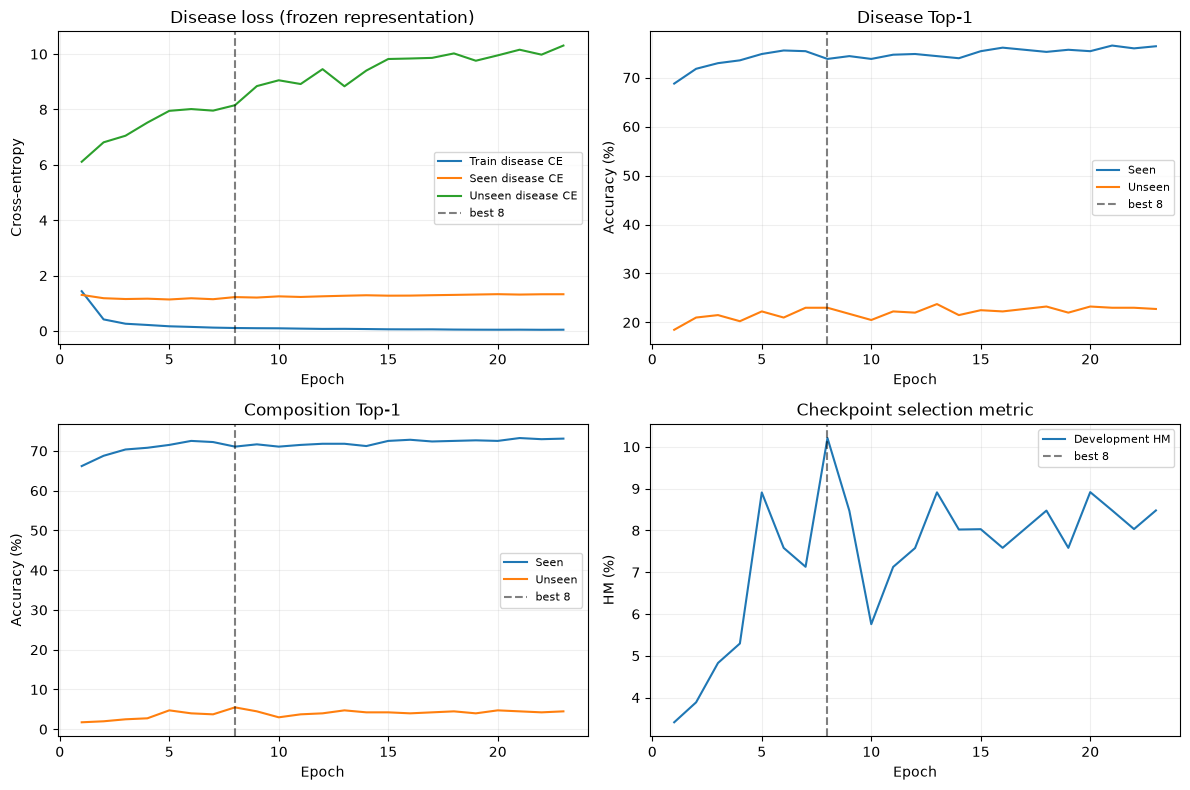

PASS: Frozen backbone / crop state is identical to Exp09 source checkpoint
FINISHED exp18_crt_seed123 best epoch 8 saved c:\AML\ML_Project\Baseline2\outputs\exp18_crt_seed123
Exp18 repeat training closed. Development-only audit follows; no second training job.


In [7]:
frames,verified_report=validate_development_splits(SPLIT_DIR)
candidates=make_candidates(CONFIG["candidate_mode"],CONFIG["candidate_catalog"])
require_candidate_coverage(candidates,list(frames.values()))
for nm,frame in frames.items():
    expected={"train_fit":6905,"val_seen":695,"val_unseen":400}[nm]
    if len(frame)!=expected:raise ValueError(f"Unexpected {nm} count {len(frame)}")
datasets={name:DPDDataset(frame,IMAGE_ROOT,
    training_transform(CONFIG) if name=="train_fit" else evaluation_transform(CONFIG["image_size"]))
    for name,frame in frames.items()}
for ds in datasets.values():
    for path in ds.paths:
        with Image.open(path) as im:im.convert("RGB").load()
verified_report["image_paths_checked"]=True
verified_report["image_decoding_checked"]=True
sampler,exposure_table=make_tempered_disease_sampler(frames["train_fit"],alpha=0.5,seed=CONFIG["seed"])
print("Exp18 cRT frozen representation, disease-head-only training with alpha=0.5 sampler")
loaders={name:make_loader(ds,CONFIG,
    shuffle=False,sampler=(sampler if name=="train_fit" else None))
    for name,ds in datasets.items()}
seed_everything(CONFIG["seed"])
example=next(iter(loaders["val_seen"]))
assert tuple(example["image"].shape[1:])==(3,224,224)
model,history,metrics,experiment_dir=fit_crt_stage1(
    CONFIG,loaders["train_fit"],loaders["val_seen"],loaders["val_unseen"],
    candidates,verified_report,class_mappings,composition_mapping)
exposure_table.to_csv(experiment_dir/"expected_disease_sampling_exposure.csv",index=False)
print("FINISHED",EXPERIMENT_TO_RUN,"best epoch",metrics["epoch"],"saved",experiment_dir)
del loaders,datasets,example,sampler,model
gc.collect();plt.close("all")
if DEVICE.type=="cuda":torch.cuda.empty_cache()
print("Exp18 repeat training closed. Development-only audit follows; no second training job.")


## 8. Evaluate saved best checkpoint (development-only)

Use the same crop/disease class mappings and all 9,625 candidate pairs as Exp09. Saves validation predictions and error breakdown.


In [8]:
if RUN_AUTO_AUDIT:
    ckpt = EXPERIMENT_DIR / "best_development.pt"
    if not ckpt.is_file():
        raise FileNotFoundError("Selected checkpoint missing; cannot audit")
    diagnostic_model, saved = load_checkpoint(ckpt, DEVICE)
    assert saved["stage"] == 1 and saved["config"]["experiment_id"] == EXPERIMENT_TO_RUN
    assert saved["development_split"]["sha256"] == split_report["sha256"], "Split mismatch"
    saved_candidates = torch.as_tensor(saved["candidate_pairs"], dtype=torch.long)
    train_pair_set = set(map(tuple, frames["train_fit"][["crop_id", "disease_id"]].to_numpy().tolist()))
    predictions, audit_summary = {}, []
    for split in ("val_seen", "val_unseen"):
        ds = DPDDataset(frames[split], IMAGE_ROOT, evaluation_transform(CONFIG["image_size"]))
        dl = make_loader(ds, saved["config"], shuffle=False)
        metrics_split, records = evaluate_loader(diagnostic_model, dl, DEVICE, saved_candidates,
                                                   amp=saved["config"]["amp"], collect_predictions=True)
        tab = pd.DataFrame(records)
        assert len(tab) == len(frames[split]) and tab.filename.is_unique
        tab["crop_correct"] = tab.crop_id == tab.predicted_crop_id
        tab["disease_correct"] = tab.disease_id == tab.predicted_disease_id
        tab["crop_only_wrong"] = ~tab.crop_correct & tab.disease_correct
        tab["disease_only_wrong"] = tab.crop_correct & ~tab.disease_correct
        tab["both_wrong"] = ~tab.crop_correct & ~tab.disease_correct
        tab["predicted_pair_seen_in_training"] = [
            (int(c), int(d)) in train_pair_set
            for c,d in zip(tab.predicted_pair_crop_id, tab.predicted_pair_disease_id)]
        if int((tab.crop_correct & tab.disease_correct).sum()) != round(metrics_split["composition_top1"] * len(tab)):
            print("Warning: independent head argmax and composition ranking differ (possible score ties).")
        predictions[split] = tab
        tab.to_csv(EXPERIMENT_DIR / f"{split}_error_predictions.csv", index=False)
        audit_summary.append({"split":split, "n":len(tab),
            "crop_top1":metrics_split["crop_top1"],
            "disease_top1":metrics_split["disease_top1"],
            "composition_top1":metrics_split["composition_top1"],
            "composition_top5":metrics_split["composition_top5"],
            "disease_only_wrong_count":int(tab.disease_only_wrong.sum()),
            "crop_only_wrong_count":int(tab.crop_only_wrong.sum()),
            "both_wrong_count":int(tab.both_wrong.sum()),
            "predicted_pair_seen_in_training_rate":float(tab.predicted_pair_seen_in_training.mean())})
    audit_table = pd.DataFrame(audit_summary)
    audit_table.to_csv(EXPERIMENT_DIR / "task_error_breakdown.csv",index=False)
    display(audit_table)
    print("Saved Experiment predictions + error breakdown")
else:
    print("Auto audit disabled. No evaluation performed.")


,split,n,crop_top1,disease_top1,composition_top1,composition_top5,disease_only_wrong_count,crop_only_wrong_count,both_wrong_count,predicted_pair_seen_in_training_rate
0,val_seen,695,0.889209,0.738129,0.710791,0.870504,124,19,58,0.920863
1,val_unseen,400,0.705000,0.230000,0.055000,0.147500,260,70,48,0.812500


Saved Experiment predictions + error breakdown


## 9. Per-class accuracy: did frozen-backbone cRT improve minority diseases?

Focus on disease Top-1, disease-only mistakes and composition HM on held-out pairs. Crops' model parameters are unchanged, but classification performance across transformed images may exhibit numerical ties. Compare per-class true labels and confusion matrices.


In [9]:
if RUN_AUTO_AUDIT:
    class_counts = {}
    for task in ("crop", "disease", "composition"):
        idcol, namecol = f"{task}_id", f"{task}_name"
        table = (frames["train_fit"].groupby([idcol, namecol], dropna=False)
                 .size().rename("train_images").reset_index()
                 .sort_values(["train_images",namecol], ascending=[True,True]))
        for split in ("val_seen", "val_unseen"):
            counts = frames[split].groupby(idcol).size().rename(f"{split}_images")
            table = table.join(counts,on=idcol)
        table[["val_seen_images","val_unseen_images"]] = table[["val_seen_images","val_unseen_images"]].fillna(0).astype(int)
        table.to_csv(EXPERIMENT_DIR / f"{task}_class_counts.csv",index=False)
        class_counts[task] = table
        print(f"{task}: {len(table)} labels | min {int(table.train_images.min())} | median {table.train_images.median():g} | max {int(table.train_images.max())}")

    MIN_SUPPORT = 5
    per_class = {}
    for split, pred in predictions.items():
        for task in ("crop", "disease"):
            idcol, namecol, predcol = f"{task}_id", f"{task}_name", f"predicted_{task}_id"
            rows = pred.assign(_correct=(pred[idcol]==pred[predcol]).astype(int))
            score = rows.groupby(idcol).agg(n_validation=(idcol,"size"), n_correct=("_correct","sum")).reset_index()
            score["top1_accuracy"] = score.n_correct / score.n_validation
            names = class_counts[task][[idcol,namecol,"train_images"]]
            score=score.merge(names,on=idcol,how="left",validate="one_to_one")
            score["n_wrong"] = score.n_validation - score.n_correct
            errs = rows.loc[rows._correct==0]
            frequent_wrong = (errs.groupby([idcol,predcol]).size().rename("mistake_count")
               .reset_index().sort_values("mistake_count",ascending=False).drop_duplicates(idcol))
            freq_names = dict(zip(names[idcol],names[namecol]))
            frequent_wrong["most_common_wrong_prediction"] = frequent_wrong[predcol].map(freq_names)
            score=score.merge(frequent_wrong[[idcol,"most_common_wrong_prediction","mistake_count"]],
                              on=idcol,how="left")
            score=score.sort_values(["top1_accuracy","n_validation"],ascending=[True,False])
            per_class[(split,task)]=score
            score.to_csv(EXPERIMENT_DIR / f"{split}_{task}_per_class.csv",index=False)
            eligible=score.loc[score.n_validation>=MIN_SUPPORT]
            print(f"\n{split} {task}: {len(eligible)} classes with n >= {MIN_SUPPORT}")
            display(eligible[[namecol,"train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]].head(6))
            display(eligible.sort_values(["top1_accuracy","n_validation"],ascending=[False,False])
                    [[namecol,"train_images","n_validation","top1_accuracy","most_common_wrong_prediction"]].head(6))
else:
    print("Audit disabled")


crop: 55 labels | min 2 | median 38 | max 1007
disease: 175 labels | min 1 | median 8 | max 1417
composition: 313 labels | min 1 | median 6 | max 500

val_seen crop: 27 classes with n >= 5


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
4,bean,27,5,0.400000,corn
5,pepper_bell,56,7,0.714286,tomato
38,pear,94,9,0.777778,apple
49,tea,40,9,0.777778,tomato
19,coffee,121,14,0.785714,citrus
6,blackgram,49,5,0.800000,tobacco


,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
47,sugarcane,147,15,1.0,NaN
53,wheat,124,13,1.0,NaN
40,potato,133,12,1.0,NaN
32,olive,107,10,1.0,NaN
37,peanut,114,9,1.0,NaN
35,papaya,57,5,1.0,NaN



val_seen disease: 39 classes with n >= 5


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
48,green_mottle,59,5,0.200000,mosaic
53,spot,83,12,0.333333,rust
11,marssonina_blotch,75,7,0.428571,rust
15,scab,58,7,0.428571,greening
146,septoria_leaf_spot,167,15,0.533333,target_spot
18,anthracnose,44,7,0.571429,brown_rot


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
83,streak_virus,201,17,1.0,NaN
148,yellow_leaf_curl_virus,164,14,1.0,NaN
73,target_spot,87,7,1.0,NaN
126,diabrotica_speciosa,67,6,1.0,NaN
3,black_rot,31,5,1.0,NaN
119,slug,60,5,1.0,NaN


... (2 outputs left out)

,crop_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
8,tomato,1007,70,1.000000,NaN
9,wheat,124,5,1.000000,NaN
7,potato,133,70,0.928571,tomato
1,bean,27,18,0.888889,tomato
3,cassava,959,117,0.880342,corn
6,mango,100,18,0.777778,olive



val_unseen disease: 8 classes with n >= 5


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
5,spider_mites,5,70,0.000000,target_spot
3,angular_leaf_spot,7,18,0.000000,bean_rust
6,bacterial_leaf_streak,12,5,0.000000,septoria_blotch
4,bacterial_blight,27,117,0.008547,brown_spot
1,monillia_laxa,8,9,0.111111,healthy
7,late_blight,103,70,0.314286,early_blight


,disease_name,train_images,n_validation,top1_accuracy,most_common_wrong_prediction
0,healthy,1417,51,0.862745,greening
2,powdery_mildew,150,60,0.400000,sooty_mould
7,late_blight,103,70,0.314286,early_blight
1,monillia_laxa,8,9,0.111111,healthy
4,bacterial_blight,27,117,0.008547,brown_spot
5,spider_mites,5,70,0.000000,target_spot


## 10. Confusion matrices and weak/strong class visualizations

Same reporting method as previous Stage-1 experiments; figures saved in the new run folder.


In [10]:
if RUN_AUTO_AUDIT:
    for split, pred in predictions.items():
        for task in ("crop","disease"):
            idcol, namecol, predcol = f"{task}_id", f"{task}_name", f"predicted_{task}_id"
            freq = class_counts[task]
            id_to_name=dict(zip(freq[idcol],freq[namecol]))
            all_ids=sorted(freq[idcol].unique().tolist())
            full = pd.crosstab(pred[idcol],pred[predcol]).reindex(index=all_ids,columns=all_ids,fill_value=0)
            full.index=[f"{i}: {id_to_name[i]}" for i in all_ids]
            full.columns=[f"{i}: {id_to_name[i]}" for i in all_ids]
            full.to_csv(EXPERIMENT_DIR / f"{split}_{task}_full_confusion.csv")
            qualified=per_class[(split,task)].query("n_validation >= @MIN_SUPPORT")
            selections={"weakest":qualified.head(6),
                        "strongest":qualified.sort_values(["top1_accuracy","n_validation"],ascending=[False,False]).head(6)}
            for label,selected in selections.items():
                chosen=selected[idcol].tolist()
                small=pred.loc[pred[idcol].isin(chosen),[idcol,predcol]].copy()
                common=(small.loc[small[idcol]!=small[predcol],predcol]
                        .value_counts().head(5).index.tolist())
                columns=["Correct"]+[f"{int(p)}: {id_to_name.get(int(p),p)}" for p in common]+["Other wrong"]
                counts, labels=[],[]
                for target in chosen:
                    part=small.loc[small[idcol]==target]
                    vals=[int((part[predcol]==target).sum())]
                    vals += [int(((part[predcol]==p)&(part[predcol]!=target)).sum()) for p in common]
                    vals.append(int(((part[predcol]!=target)&(~part[predcol].isin(common))).sum()))
                    assert sum(vals)==len(part), "Confusion row counts do not match support"
                    counts.append(vals)
                    labels.append(f"{id_to_name[target]} (n={len(part)})")
                matrix=pd.DataFrame(counts,index=labels,columns=columns)
                matrix.to_csv(EXPERIMENT_DIR / f"{split}_{task}_{label}_confusion_summary.csv")
                fig,ax=plt.subplots(figsize=(max(8,2+len(columns)*1.2),max(4, len(chosen)*0.6+1)))
                im=ax.imshow(matrix.to_numpy(), aspect="auto")
                ax.set_xticks(np.arange(len(columns)),labels=columns,rotation=45,ha="right",fontsize=8)
                ax.set_yticks(np.arange(len(labels)),labels=labels,fontsize=9)
                for (i,j),value in np.ndenumerate(matrix.to_numpy()):
                    ax.text(j,i,str(value),ha="center",va="center",fontsize=8)
                ax.set_title(f"{EXPERIMENT_TO_RUN} {split} {task} — {label} classes (counts)")
                fig.colorbar(im,ax=ax,label="Images")
                fig.tight_layout()
                fig.savefig(EXPERIMENT_DIR / f"{split}_{task}_{label}_confusion_summary.png",dpi=135,bbox_inches="tight")
                plt.close(fig)
    print("Saved all eight weak/strong confusion summary charts, CSVs and four full confusion matrices")
else:
    print("Audit disabled")


Saved all eight weak/strong confusion summary charts, CSVs and four full confusion matrices


## 11. Compare Exp17 and Exp18 conditional head-seed repeats

Evaluate the frozen-Exp09-parent cRT recipe at seeds **42 (original Exp17), 123, 2026**. Mean ± SD is computed over whichever runs are available; **all 3 seeds are required** for the planned three-run summary. This estimates *head/sampler/augmentation seed sensitivity conditional on one pretrained representation*, not full end-to-end model-seed stability. No official test.


In [11]:
records = []
for name, seed, path in [
    ("Exp17 cRT original", 42, OUTPUT_ROOT / "exp17_crt_disease_alpha05"),
    ("Exp18 cRT repeat", 123, OUTPUT_ROOT / "exp18_crt_seed123"),
    ("Exp18 cRT repeat", 2026, OUTPUT_ROOT / "exp18_crt_seed2026"),
]:
    fp = path / "validation_metrics.json"
    if not fp.exists():
        print("Not yet available:", fp)
        continue
    obj = json.loads(fp.read_text(encoding="utf-8"))
    records.append({
        "experiment": name, "seed": seed, "best_epoch": obj["epoch"],
        "seen_comp": obj["seen"]["composition_top1"],
        "unseen_comp": obj["unseen"]["composition_top1"],
        "HM": obj["composition_harmonic_mean"],
        "unseen_crop": obj["unseen"]["crop_top1"],
        "unseen_disease": obj["unseen"]["disease_top1"],
        "unseen_correct_of_400": round(obj["unseen"]["composition_top1"] * 400),
    })
comparison = pd.DataFrame(records).sort_values("seed").reset_index(drop=True)
comparison.to_csv(EXPERIMENT_DIR / "crt_head_seed_comparison.csv", index=False)
display(comparison)

metric_cols = ["seen_comp", "unseen_comp", "HM", "unseen_crop", "unseen_disease"]
if len(comparison) >= 2:
    summary = comparison[metric_cols].agg(["mean", "std"]).transpose()
else:
    summary = comparison[metric_cols].agg(["mean"]).transpose()
    summary["std"] = float("nan")
summary.to_csv(EXPERIMENT_DIR / "crt_head_seed_mean_std.csv")
all_complete = set(comparison["seed"].tolist()) == {42, 123, 2026}
print("All three cRT head-seed runs available:", all_complete)
print("Conditional cRT head-seed mean ± sample SD (fractions, not percent):")
display(summary)

rare = per_class[("val_unseen", "disease")].loc[
    per_class[("val_unseen", "disease")].n_validation >= 5
].sort_values("top1_accuracy").head(8)
cols = ["disease_name", "train_images", "n_validation", "top1_accuracy", "most_common_wrong_prediction"]
msg = [
    "# Exp18 — cRT head-seed conditional repeat (development only)", "",
    f"- Current run: {EXPERIMENT_TO_RUN}, seed={CONFIG['seed']}",
    "- Parent: SAME trained Exp09 seed42 ResNet50 backbone/crop head as original Exp17.",
    "- cRT recipe: frozen backbone/crop; reset disease linear head; tempered disease sampler alpha=0.5.",
    "- Head/augmentation/sampler seeds: 42 (Exp17), 123 and 2026 (Exp18).",
    "- The shared frozen parent makes these conditional head-seed repeats, NOT fully independent full-model seeds.",
    "- Same fixed 6,905 / 695 / 400 development split and all 9,625 candidate pairs.",
    "- Best checkpoint selected within each run by development seen/unseen composition HM.",
    "- No Stage 2, official test, or test-driven parameter selection.", "",
    "## Saved checkpoint comparison", "",
    "```text", comparison.to_string(index=False), "```", "",
    "## Across available seeds (mean and sample SD; values are fractions)", "",
    "```text", summary.to_string(), "```", "",
    f"- All three seeds complete: {all_complete}", "",
    "## Weakest unseen disease classes in this run (support >=5)", "",
    "```text", rare[cols].to_string(index=False), "```", "",
    "## Interpretation", "",
    "- A higher development HM at one seed does not establish robust improvement.",
    "- Check both variation in disease Top-1 and variation in exact unseen pair successes.",
    "- Train separately seeded Exp09 backbones if full end-to-end seed stability is required.",
]
(EXPERIMENT_DIR / "leader_crt_head_seed_summary.md").write_text("\n".join(msg) + "\n", encoding="utf-8")
if "diagnostic_model" in globals():
    del diagnostic_model
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()


Not yet available: c:\AML\ML_Project\Baseline2\outputs\exp18_crt_seed2026\validation_metrics.json


,experiment,seed,best_epoch,seen_comp,unseen_comp,HM,unseen_crop,unseen_disease,unseen_correct_of_400
0,Exp17 cRT original,42,20,0.725180,0.050,0.09355,0.705,0.24,20
1,Exp18 cRT repeat,123,8,0.710791,0.055,0.10210,0.705,0.23,22


All three cRT head-seed runs available: False
Conditional cRT head-seed mean ± sample SD (fractions, not percent):


,mean,std
seen_comp,0.717986,0.010174
unseen_comp,0.052500,0.003536
HM,0.097825,0.006046
unseen_crop,0.705000,0.000000
unseen_disease,0.235000,0.007071


## 12. Interpretation and next decision

After seed123, repeat once with selector `exp18_crt_seed2026`. Compare both with Exp17 seed42. A three-seed mean ± SD estimates **cRT classifier-stage randomness with the Exp09 frozen parent fixed**, not full end-to-end robustness. If repeated cRT gains disappear, do not assume Exp17's one-seed result is a general improvement. Once selection decisions are locked, proceed to separately planned Stage 2 and official test.
